Processing 3 Sentinel directories found.
Saved plot to: vegetation_comparison_S2_2017-07-12.png
Saved plot to: vegetation_comparison_S2_2018-07-12.png
Saved plot to: vegetation_comparison_S2_2019-07-12.png

Pixel area check: 87.5
Processing 6 Google Earth images found.
Saved plot to: google_earth_land_mask_qa.png
Saved plot to: time_series.png
S2_2017-07-12: veg area ours/pipeline = 0.614/0.789 km^2 | agreement = 0.9858| mean NDVI inside/outside pipeline veg = 0.519/-0.192 | 
S2_2018-07-12: veg area ours/pipeline = 0.674/0.807 km^2 | agreement = 0.9892| mean NDVI inside/outside pipeline veg = 0.564/-0.123 | 
S2_2019-07-12: veg area ours/pipeline = 0.772/0.985 km^2 | agreement = 0.9827| mean NDVI inside/outside pipeline veg = 0.540/-0.103 | 


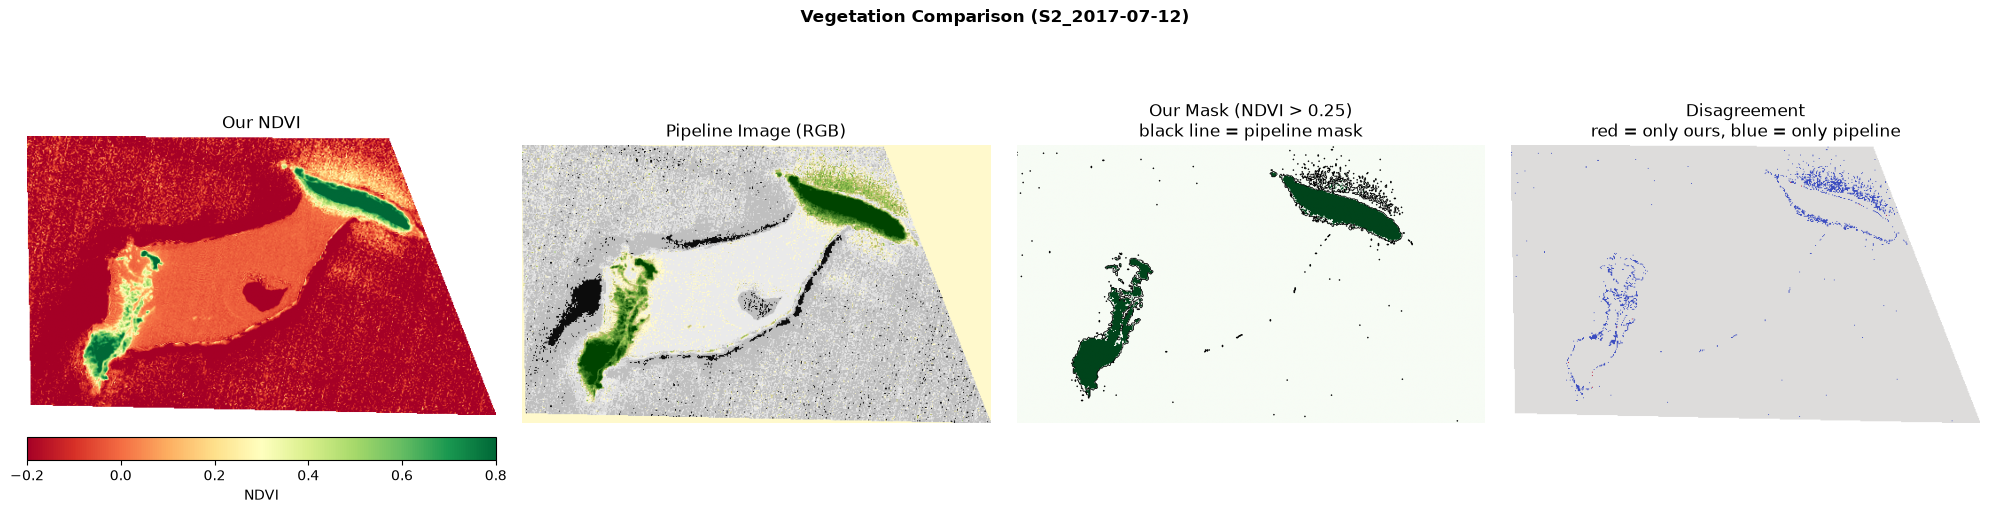

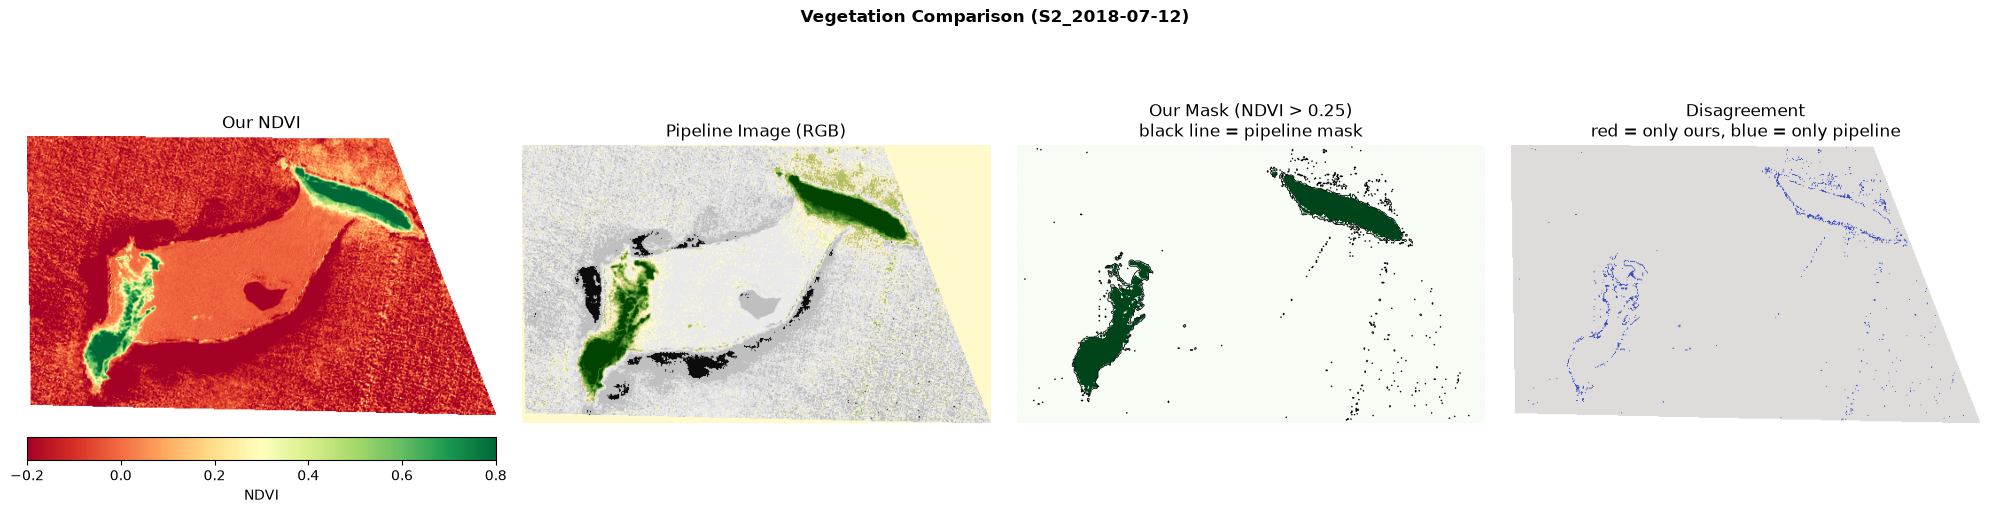

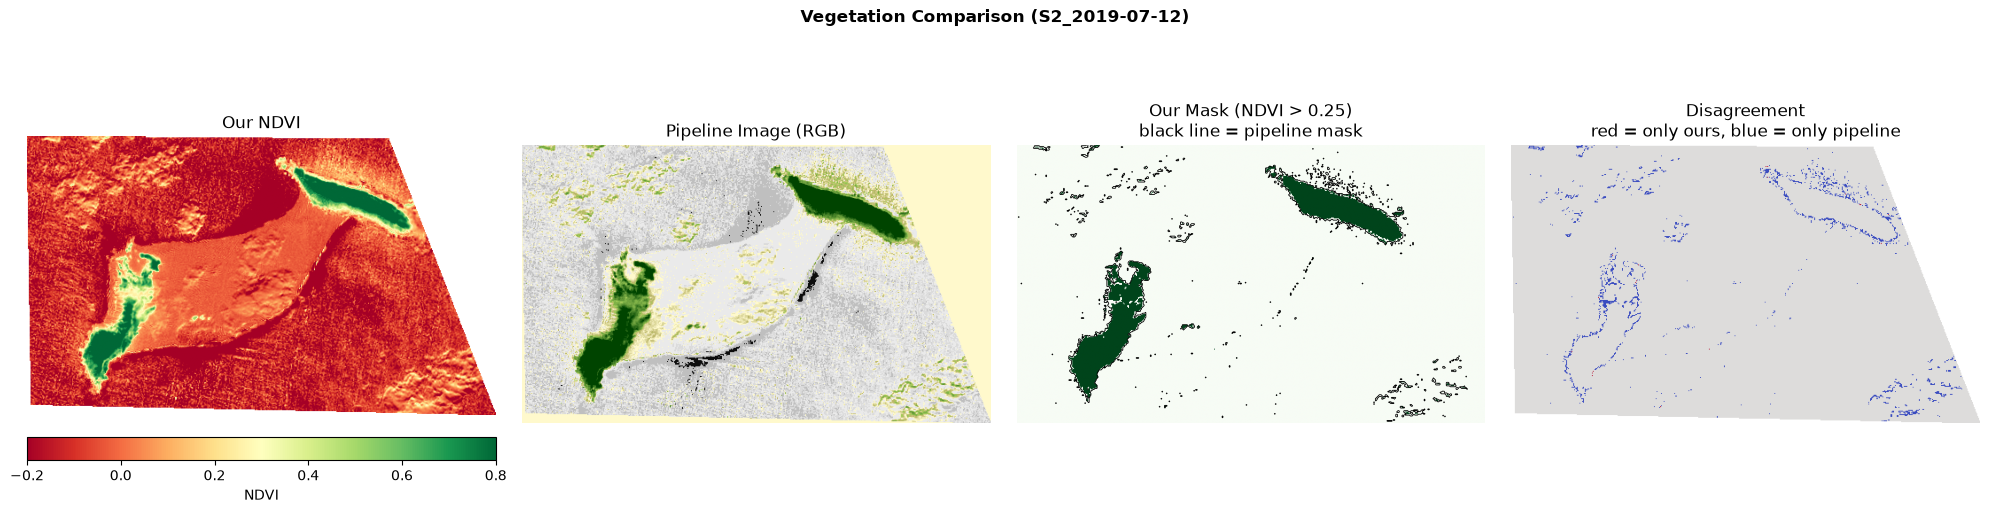

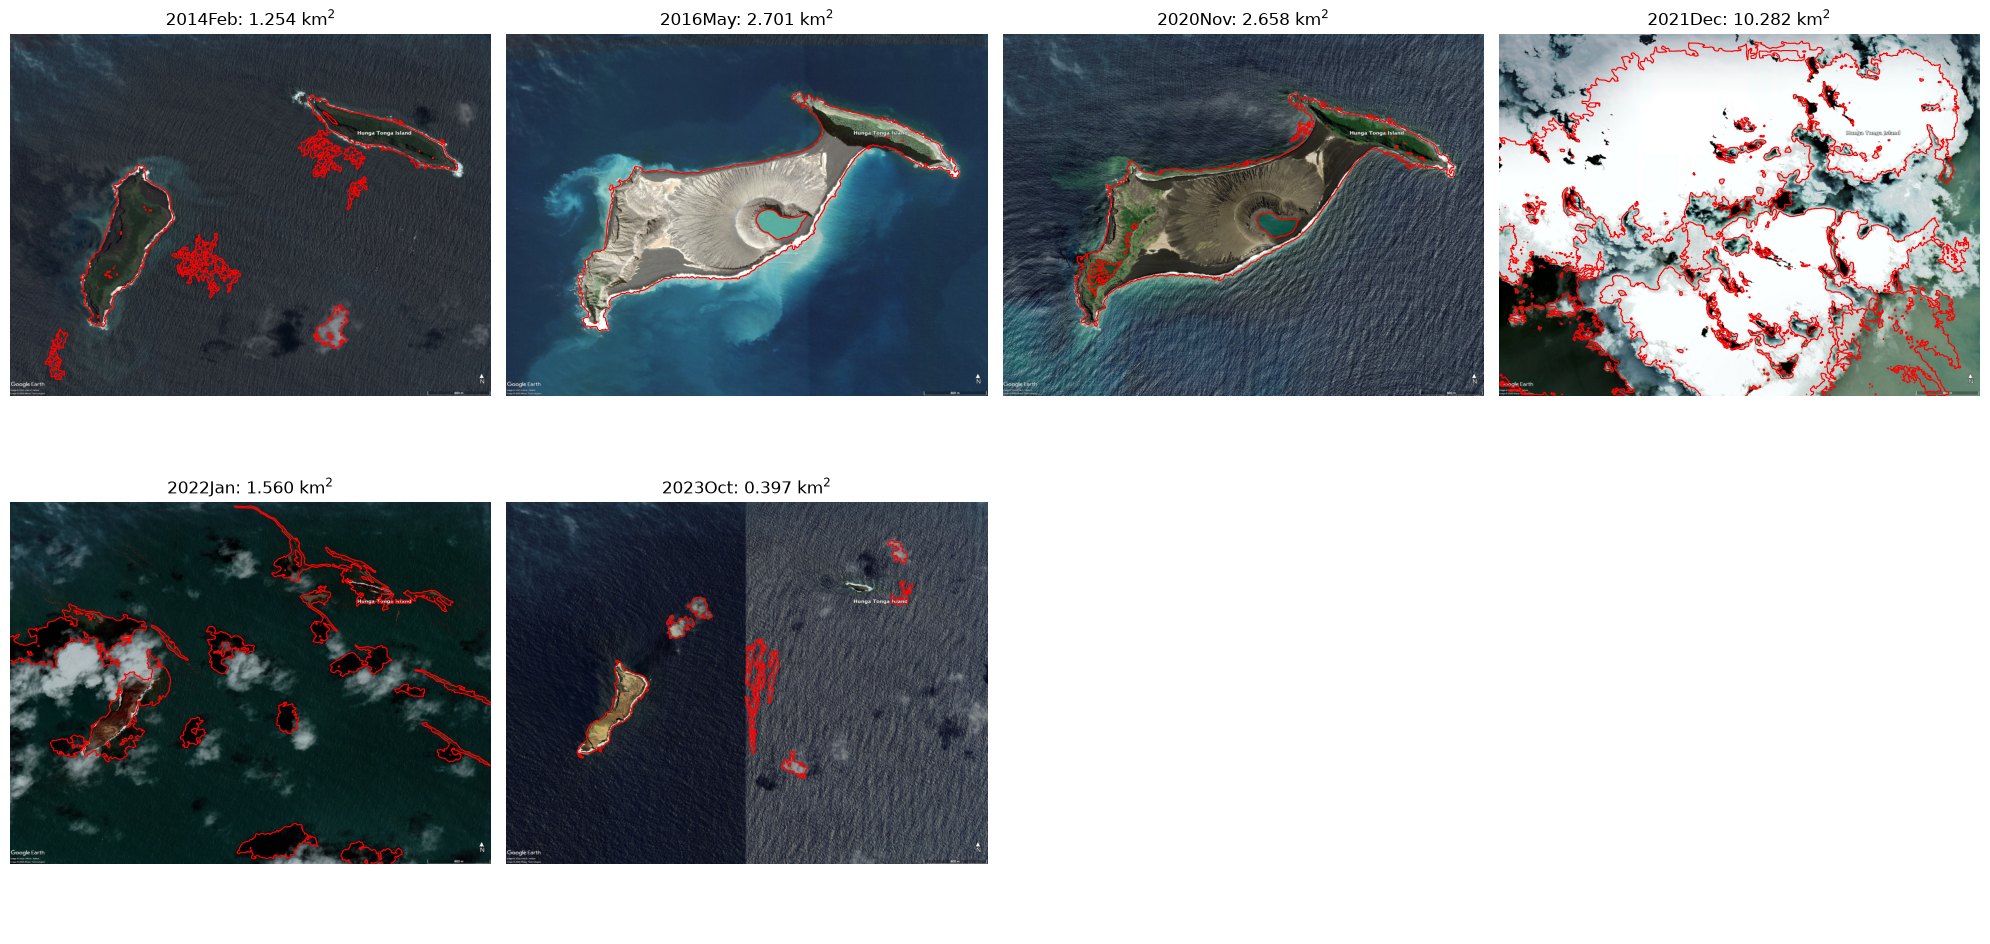

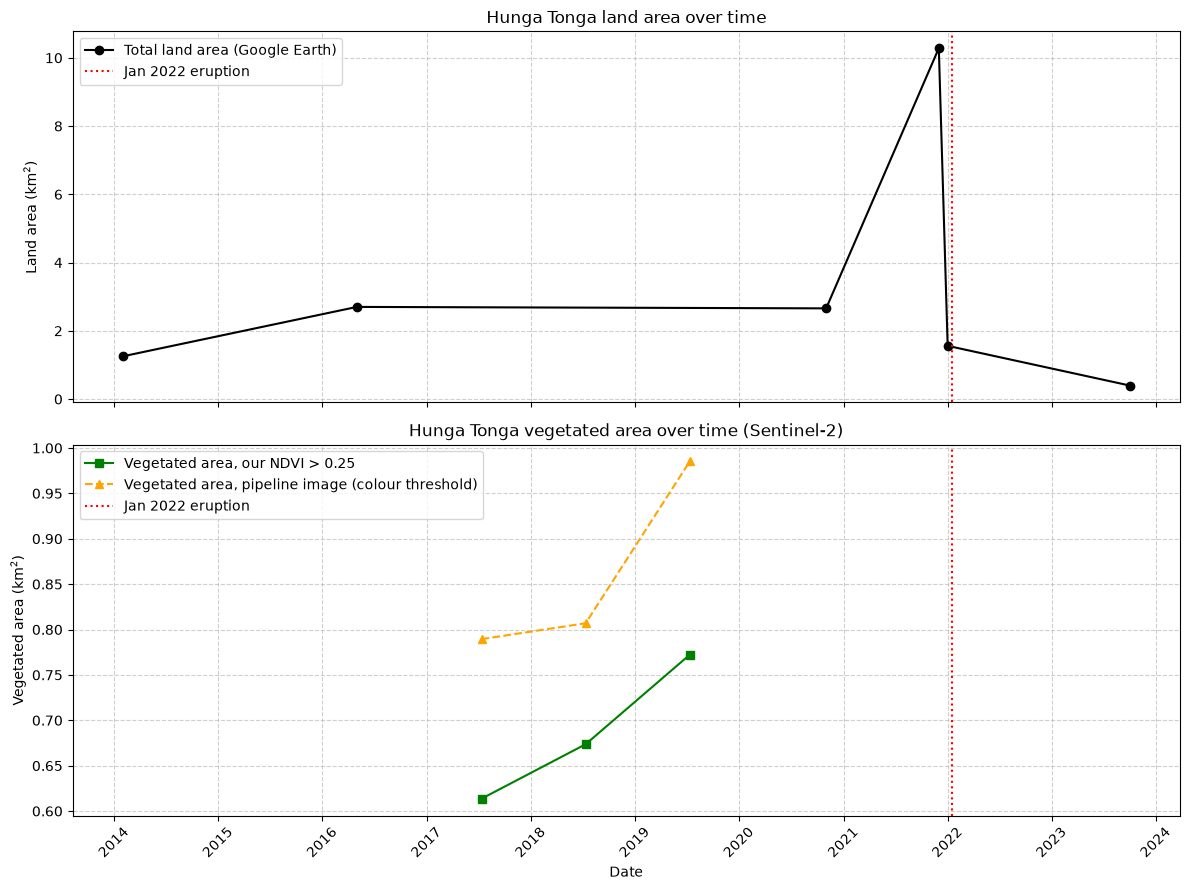

In [ ]:
"""Hunga Tonga analysis: Google Earth land area and Sentinel-2 vegetation area vs time.
  1. Land area vs time from the Google Earth images (Measure the scale bar to pixel size with an outside tool)
  2. Vegetated area vs time from Sentinel-2 (angular pixel size -> m^2).
  3. Compare and contrast our own NDVI with the pipeline-provided product,
     with quantitative measures of the differences.
  Author: Ta'Nasia Coleman
"""
import glob
import os

from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import rasterio

from scipy import ndimage as ndi



# ----------------------------------------------------
# CONFIGURATION
# ----------------------------------------------------
BASE_PATH = Path("sentinel-data")
OUTPUT_DIR = Path("sentinel-processed") 
METERS_PER_LAT_DEGREE = 111132.0

# Sentinel-2
NDVI_THRESHOLD = 0.25    # NDVI above this counts as vegetation
GREEN_MARGIN = 0.15      # pipeline RGB: how much greener than red/blue = vegetation (tune by eye)

# Google Earth
SCALE_BAR_METERS = 600.0
SCALE_BAR_PIXELS = 309           # default scale bar length in pixels
SCALE_BAR_OVERRIDES = {}         # per-image fix if the zoom differs, e.g. {"2019Jul": 295}
WATER_BLUE_MARGIN = 10           # pixel is water if (blue - red) > this, on the 0-255 scale
WATER_MARGIN_OVERRIDES = {}      # per-image fix, e.g. {"2017Jul": 20}
SMOOTH_SIGMA = 2                 # blur (px) before classifying, to suppress glint speckle
MIN_LAND_BLOB_PX = 4000           # drop land blobs smaller than this (placemarks, specks)
CROP_BOTTOM_PX = 200               # rows to cut off the bottom (scale bar / text overlay)
ROI_DEFAULT = (0.0, 1.0, 0.0, 1.0)   # region of interest (x0, x1, y0, y1) as image fractions
ROI_OVERRIDES = {}               # per-image, e.g. {"2017Jul": (0.0, 0.48, 0.0, 1.0)} to skip a tile seam

ERUPTION_DATE = datetime(2022, 1, 15)


# ----------------------------------------------------
# SHARED HELPERS
# ----------------------------------------------------
def save_figure(fig, name):
    OUTPUT_DIR.mkdir(exist_ok=True)
    fig.savefig(OUTPUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    print(f"Saved plot to: {name}.png")

    
def match_shapes(*arrays):
    """Crop 2D arrays to a common (smallest) shape."""
    h = min(a.shape[0] for a in arrays)
    w = min(a.shape[1] for a in arrays)
    return [a[:h, :w] for a in arrays]




# ----------------------------------------------------
# PART A: SENTINEL-2 VEGETATION
# ----------------------------------------------------
def sentinel_pixel_area_m2(src):
    """Pixel area in m^2 from angular resolution and image latitude."""
    res_x, res_y = src.res                      # degrees
    bounds = src.bounds
    lat_rad = np.radians((bounds.bottom + bounds.top) / 2.0)
    pixel_height_m = res_y * METERS_PER_LAT_DEGREE
    pixel_width_m = res_x * METERS_PER_LAT_DEGREE * np.cos(lat_rad)
    return abs(pixel_height_m * pixel_width_m)


def compute_ndvi(folder):
    """Our own NDVI = (B8 - B4) / (B8 + B4) from the raw bands.

    Returns (ndvi, pixel_area_m2). No-data pixels (both bands 0) are NaN.
    """
    with rasterio.open(os.path.join(folder, "Sentinel-2_L2A_B04_Raw.tiff")) as f4, \
         rasterio.open(os.path.join(folder, "Sentinel-2_L2A_B08_Raw.tiff")) as f8:
        red = f4.read(1).astype(float)
        nir = f8.read(1).astype(float)
        area_m2 = sentinel_pixel_area_m2(f8)

    red, nir = match_shapes(red, nir)
    denom = nir + red
    no_data = denom == 0
    ndvi = np.where(no_data, np.nan, (nir - red) / np.where(no_data, 1, denom))
    return ndvi, area_m2


def read_pipeline_rgb(folder):
    """The pipeline 'NDVI' tiff is a 3-band RGB render, not an index."""
    with rasterio.open(os.path.join(folder, "Sentinel-2_L2A_NDVI.tiff")) as src:
        r, g, b = src.read([1, 2, 3]).astype(float)
    return r, g, b


def pipeline_vegetation_mask(r, g, b, margin=GREEN_MARGIN):
    """Vegetation = clearly greener than red and blue (white/grey water is excluded)."""
    return ((g - r) > margin) & ((g - b) > margin)


# ----------------------------------------------------
# PART C: COMPARISON (OUR NDVI vs PIPELINE)
# ----------------------------------------------------
def compare_to_pipeline(ndvi, pipe_mask, thresholds):
    """Quantitative comparison of our NDVI mask with the pipeline mask.

    Includes a threshold sweep: which NDVI cut best reproduces the pipeline mask?
    """
    valid = np.isfinite(ndvi)
    my_mask = np.nan_to_num(ndvi, nan=-1) > NDVI_THRESHOLD
    v, pm = ndvi[valid], pipe_mask[valid]


    return {
        "valid": valid,
        "my_mask": my_mask,
        "agreement": np.mean(my_mask[valid] == pm),
        "mean_ndvi_in_pipe_veg": v[pm].mean() if pm.any() else np.nan,
        "mean_ndvi_outside": v[~pm].mean() if (~pm).any() else np.nan,
        "thresholds": thresholds,
    }


def process_sentinel_folder(folder, thresholds):
    """Everything we need from one Sentinel-2 date."""
    folder_name = os.path.basename(folder)
    date = datetime.strptime(folder_name.split("_")[1], "%Y-%m-%d")

    ndvi, area_m2 = compute_ndvi(folder)
    r, g, b = read_pipeline_rgb(folder)
    ndvi, r, g, b = match_shapes(ndvi, r, g, b)
    pipe_mask = pipeline_vegetation_mask(r, g, b)

    comp = compare_to_pipeline(ndvi, pipe_mask, thresholds)
    valid = comp["valid"]
    return {
        "name": folder_name,
        "date": date,
        "pixel_area_m2": area_m2,
        "our_area_km2": comp["my_mask"][valid].sum() * area_m2 / 1e6,
        "pipe_area_km2": pipe_mask[valid].sum() * area_m2 / 1e6,
        "comparison": comp,
        "ndvi": ndvi,
        "rgb": np.dstack([r, g, b]).clip(0, 1),
        "pipe_mask": pipe_mask,
    }


def plot_mask_comparison(res):
    """4 panels: our NDVI, pipeline image, our mask (+ pipeline outline), disagreement."""
    comp = res["comparison"]
    diff = comp["my_mask"].astype(int) - res["pipe_mask"].astype(int)
    diff = np.where(comp["valid"], diff, np.nan)

    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    fig.suptitle(f"Vegetation Comparison ({res['name']})", weight="bold", y=1.02)

    im = axes[0].imshow(res["ndvi"], cmap="RdYlGn", vmin=-0.2, vmax=0.8)
    axes[0].set_title("Our NDVI")
    fig.colorbar(im, ax=axes[0], orientation="horizontal", pad=0.05, label="NDVI")

    axes[1].imshow(res["rgb"])
    axes[1].set_title("Pipeline Image (RGB)")

    axes[2].imshow(comp["my_mask"], cmap="Greens", vmin=0, vmax=1)
    axes[2].contour(res["pipe_mask"].astype(float), levels=[0.5], colors="k", linewidths=0.6)
    axes[2].set_title(f"Our Mask (NDVI > {NDVI_THRESHOLD})\nblack line = pipeline mask")

    axes[3].imshow(diff, cmap="coolwarm", vmin=-1, vmax=1)
    axes[3].set_title("Disagreement\nred = only ours, blue = only pipeline")

    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    save_figure(fig, f"vegetation_comparison_{res['name']}") 






# ----------------------------------------------------
# PART B: GOOGLE EARTH LAND AREA
# ----------------------------------------------------

def land_mask_from_rgb(rgb, blue_margin):
    # Smooth all bands at once instead of looping
    smooth = ndi.gaussian_filter(rgb[:3], sigma=(0, SMOOTH_SIGMA, SMOOTH_SIGMA))
    
    # Water is blue > red + margin. Land is the inverse (~).
    land = (smooth[2] - smooth[0]) <= blue_margin
    land = ndi.binary_opening(land, iterations=2)
    
    # Label blobs and filter out ones smaller than MIN_LAND_BLOB_PX
    labels, _ = ndi.label(land)
    sizes = np.bincount(labels.ravel())
    
    # Set background (0) and small blobs to False
    keep_labels = np.flatnonzero(sizes >= MIN_LAND_BLOB_PX)
    keep_labels = keep_labels[keep_labels > 0] 
    
    return np.isin(labels, keep_labels)


def land_area_from_google_image(path):
    with rasterio.open(path) as src:
        # Crop the bottom metadata/scale bar area directly during read
        rgb = src.read((1, 2, 3), out_shape=(3, src.height - CROP_BOTTOM_PX, src.width)).astype(float)
        
    h, w = rgb.shape[1:]
    x0, x1, y0, y1 = ROI_OVERRIDES.get(path.stem, ROI_DEFAULT)
    
    # Create the Region of Interest (ROI) mask using meshgrid/coordinate indexing
    y, x = np.ogrid[:h, :w]
    roi = (y >= int(y0 * h)) & (y < int(y1 * h)) & (x >= int(x0 * w)) & (x < int(x1 * w))
    
    # Isolate land within the ROI
    margin = WATER_MARGIN_OVERRIDES.get(path.stem, WATER_BLUE_MARGIN)
    land_mask = land_mask_from_rgb(rgb, margin) & roi
    
    # Calculate area
    scale_pixels = SCALE_BAR_OVERRIDES.get(path.stem, SCALE_BAR_PIXELS)
    pixel_size_km = (SCALE_BAR_METERS / scale_pixels) / 1000.0
    area_km2 = land_mask.sum() * (pixel_size_km ** 2)
    
    # Prepare normalized image for plotting (H, W, C)
    image = np.moveaxis(rgb, 0, -1).clip(0, 255) / 255.0
    
    return area_km2, image, land_mask



def analyse_google_earth(folder):
    """Process every image and return results sorted chronologically."""
    files = list(Path(folder).glob("*.jpg"))
    print(f"Processing {len(files)} Google Earth images found.")
    records = []
    for path in files:
        date = datetime.strptime(path.stem, "%Y%b")
        area, image, mask = land_area_from_google_image(path)
        records.append({"name": path.stem, "date": date, "area_km2": area,
                        "image": image, "mask": mask})
    # File names sort alphabetically by month ("Apr" < "Jan"), so sort by real date
    return sorted(records, key=lambda rec: rec["date"])


def plot_google_qa(records, ncols=4):
    """Sanity check on EVERY image: red outline = what we are calling land."""
    nrows = int(np.ceil(len(records) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 5 * nrows), squeeze=False)
    for ax, rec in zip(axes.ravel(), records):
        ax.imshow(rec["image"])
        ax.contour(rec["mask"].astype(float), levels=[0.5], colors="red", linewidths=0.8)
        ax.set_title(f"{rec['name']}: {rec['area_km2']:.3f} km$^2$")
    for ax in axes.ravel():
        ax.axis("off")
    plt.tight_layout()
    save_figure(fig, "google_earth_land_mask_qa") 



# ----------------------------------------------------
# TIME-SERIES PLOTS
# ----------------------------------------------------
def plot_time_series(google, sentinel):
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 9), sharex=True)

    ax1.plot([r["date"] for r in google], [r["area_km2"] for r in google],
             color="black", marker="o", label="Total land area (Google Earth)")
    ax1.set_ylabel("Land area ($\\mathrm{km}^2$)")
    ax1.set_title("Hunga Tonga land area over time")

    dates = [r["date"] for r in sentinel]
    ax2.plot(dates, [r["our_area_km2"] for r in sentinel], color="green", marker="s",
             label=f"Vegetated area, our NDVI > {NDVI_THRESHOLD}")
    ax2.plot(dates, [r["pipe_area_km2"] for r in sentinel], color="orange", marker="^",
             linestyle="--", label="Vegetated area, pipeline image (colour threshold)")
    ax2.set_ylabel("Vegetated area ($\\mathrm{km}^2$)")
    ax2.set_xlabel("Date")
    ax2.set_title("Hunga Tonga vegetated area over time (Sentinel-2)")

    for ax in (ax1, ax2):
        ax.axvline(ERUPTION_DATE, color="red", linestyle=":", label="Jan 2022 eruption")
        ax.grid(True, linestyle="--", alpha=0.6)
        ax.legend()
    plt.setp(ax2.get_xticklabels(), rotation=45)
    plt.tight_layout()
    save_figure(fig, "time_series")  



# ----------------------------------------------------
# MAIN
# ----------------------------------------------------
def main():
    OUTPUT_DIR.mkdir(exist_ok=True)
    directories = sorted(glob.glob(str(BASE_PATH / "S2_*")))
    print(f"Processing {len(directories)} Sentinel directories found.")
    thresholds = np.arange(0.0, 0.81, 0.02)

    # Part A + C: Sentinel-2
    sentinel = []
    for folder in directories:
        res = process_sentinel_folder(folder, thresholds)
        sentinel.append(res)
        plot_mask_comparison(res)
    sentinel.sort(key=lambda r: r["date"])

    print(f"\nPixel area check: {sentinel[0]['pixel_area_m2']:.1f}")

    # Part B: Google Earth
    google = analyse_google_earth(BASE_PATH / "White_light")
    plot_google_qa(google)

    # Time series
    plot_time_series(google, sentinel)

    summary = []
    for r in sentinel:
        c = r["comparison"]
        line = (f"{r['name']}: veg area ours/pipeline = {r['our_area_km2']:.3f}/{r['pipe_area_km2']:.3f} km^2 | "
                f"agreement = {c['agreement']:.4f}| "
                f"mean NDVI inside/outside pipeline veg = {c['mean_ndvi_in_pipe_veg']:.3f}/{c['mean_ndvi_outside']:.3f} | ")
        print(line)
        summary.append(line)
    (OUTPUT_DIR / "quantitative_comparison.txt").write_text("\n".join(summary))

if __name__ == "__main__":
    main()